<a href="https://colab.research.google.com/github/LucaSchaerz/2025_Intro_Python/blob/main/FEEDBACK_SCHARZ.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

We are finding out which US states Hurricane Florence passed through using geopandas?

We apply geopandas to read in the geospatial data, plot, and analyse the track of Hurricane Florence from 30 August to 18 September 2018. The track is the archived advisory record from the National Hurricane Center; the state boundaries are a US Census Bureau cartographic boundary file.

In [7]:
# Pre-supplied: download and cache the two real data files.
import pooch

states_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/gz_2010_us_040_00_5m.json",
    known_hash="sha256:7a8c022e063a34a83f35984cde6c81992ece5983f8cc4459ed02e40687739573",
    fname="us_states.geojson",
    path=pooch.os_cache("mlees"),
)
track_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/florence.csv",
    known_hash="sha256:385691583ee41682a1c905e042c56ea362609fb04645934bdda7911c55c8b63f",
    fname="florence.csv",
    path=pooch.os_cache("mlees"),
)

# Code who dont give the good results

**ERROR N°1**

The first error I had by doing this exercice, is trying to plot the US states, but without Alaska and Hawaii. I tried several things with ```~country.contains('Hawaii'|'Alaska')``` but it returned an error, so I tried with an another panda library : ```~country.str.contains('Hawaii'|'Alaska')``` but it retruns an *AttributeError: 'GeoDataFrame' object has no attribute 'str'*.

I tried one last thing by using ```.isin()``` ```US = ~country.isin(['Hawaii', 'Alaska'])``` but this one gave me the whole table with all the variables *GEO_ID*, *STATE*, *NAME*, ... and returned *TRUE* or *FALSE* for the one I asked. So Now I had an Idea what to do. I have to search in the right column (**NAME**) and ask if **Hawaii and Alaska** where in and **filter** it again in the **GDF country**.

In code it gives us that : ```US = country[~country["NAME"].isin(["Hawaii", "Alaska"])]```

**ERROR N°2**

At the end of the code, the exercice asked to print the name of each states. Because theres a lot I imediately tought of doing a **for** loop.
```
for name in US["NAME"]:
    centroid= name.centroid
```
But then it returns me this error : *AttributeError: 'str' object has no attribute 'centroid'* Thats because NAME is not a point or a polygon --> so he does not have a centroid, so I had to add a geometry argument.

So I had to try a second time but now I unpack two things from the GDF US : the **NAME** and the **geometry** 🇰

```
for name, geometry in US:
    centroid= geometry.centroid
    ax.annotate(text=name, xy=(centroid.x, centroid.y),ha="center", fontsize=6, color="white")
```

But now it gives me a other error : *ValueError: too many values to unpack (expected 2)* Thats because the code wants to unpack all the elements in US but there are more than two, so it crashes. We want to specify wich columns we want to unpack : here **NAME** and **geometry**.

At least I managed to get it right with the **zip** function:

```
for name, geom in zip(US["NAME"], US["geometry"]):
    centroid= geom.centroid
    ax.annotate(text=name, xy=(centroid.x, centroid.y),ha="center", fontsize=6, color="white")
````

Now it works haw we wanted.

**ERROR N°3**

For the third error I encountered in this exercice, is some sort of silence error. The code doesn't give us what we are expecting. The code runs and dont give any errors, but the result is not the one we are expecting.

The issue ? The hurricane points are not on the US map. It looks like an error in the projection, or maybe the coordinates who are not correct...

If we look more closely, on the data by doing a ```florence.head(3)``` we can see something that the coordinates are positive. I really tought about it and doesn't imediately understood that in the **WGS 84** projection, all the points that are on the "left" side of greenwich are negative coordinates because the longitude is calculated in **°E** and not °E **and** °W. So I had to add one more line to have the correct position for the points. The idea is to simply substract the coordinates to 0 like this : ```florence["Long"] = 0 - florence["Long"]```.







/usr/local/lib/python3.13/dist-packages/geopandas/plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)


ValueError: too many values to unpack (expected 2)

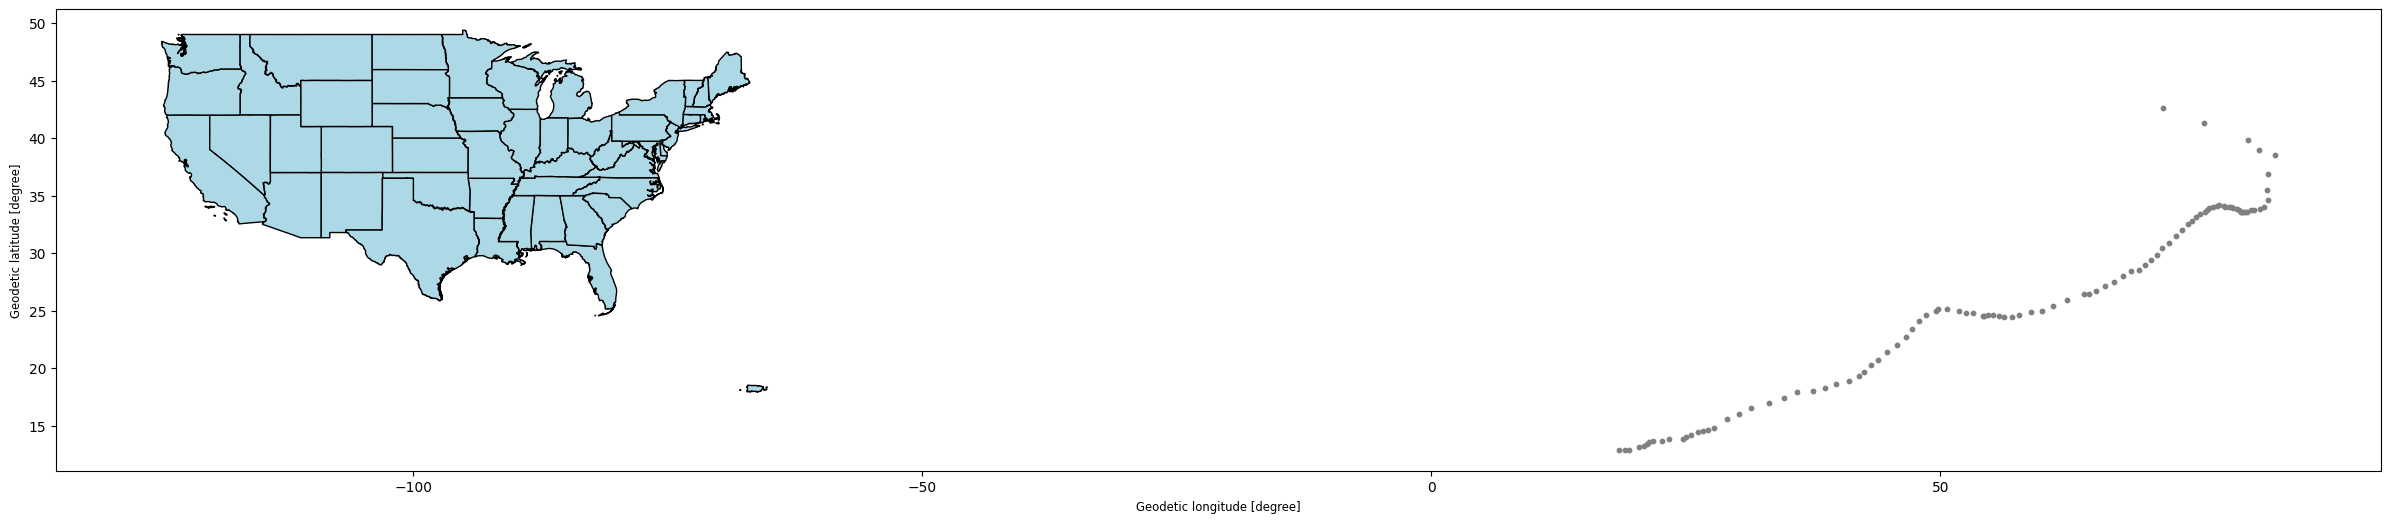

In [63]:
#Import library
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

# Read the datas with the geopandas and pandas function
country = gpd.read_file(states_path)
florence = pd.read_csv(track_path)

#prepare the data
florence = florence.drop(["AdvisoryNumber", "Forecaster", "Received"], axis=1)

# Plot the US states (Alaska and Hawaii excluded)
# **THE TREE ITERATION OF ERRORS**

# US = ~country.contains('Hawaii'|'Alaska')
# US = ~country.str.contains('Hawaii'|'Alaska')
# US = ~country.isin(['Hawaii', 'Alaska'])

# Create a geodataframe from the hurricane florence dataframe
gdf_florence = gpd.GeoDataFrame(
    florence,
    geometry=gpd.points_from_xy(florence["Long"], florence["Lat"]),
    crs="EPSG:4326")

# Plot
florence_inside = gpd.sjoin(gdf_florence, US, how='inner', predicate='intersects')

fig, ax = plt.subplots(figsize=(30, 20))
US.plot(ax=ax, color="lightblue", edgecolor="black")

# Red Marker
gdf_florence.plot(ax=ax, color="grey", markersize=10)
florence_inside.plot(ax=ax, color="red", markersize=20)

# Give a name
#for name, geom in zip(US["NAME"], US.geometry):
    #centroid = geom.centroid
    #ax.annotate(text=name, xy=(centroid.x, centroid.y),ha="center", fontsize=6, color="white")

# 1st iteration of error
#for name in US["NAME"]:
  #centroid= name.centroid
  #ax.annotate(text=name, xy=(centroid.x, centroid.y),ha="center", fontsize=6, color="white")

# 2nd iteration of error
for name, geometry in US:
  centroid= geometry.centroid
  ax.annotate(text=name, xy=(centroid.x, centroid.y),ha="center", fontsize=6, color="white")

# 3rd iteration now it works
#for name, geom in zip(US["NAME"], US["geometry"]):
  #centroid= geom.centroid
  #ax.annotate(text=name, xy=(centroid.x, centroid.y),ha="center", fontsize=6, color="white")

ax.set_xlabel("longitude (°E)")
ax.set_ylabel("latitude (°N)")
ax.set_title("Hurricane Florence")
plt.show()

#Show the intersect
florence_inside.head(30)
US.head(3)

# Code corrected

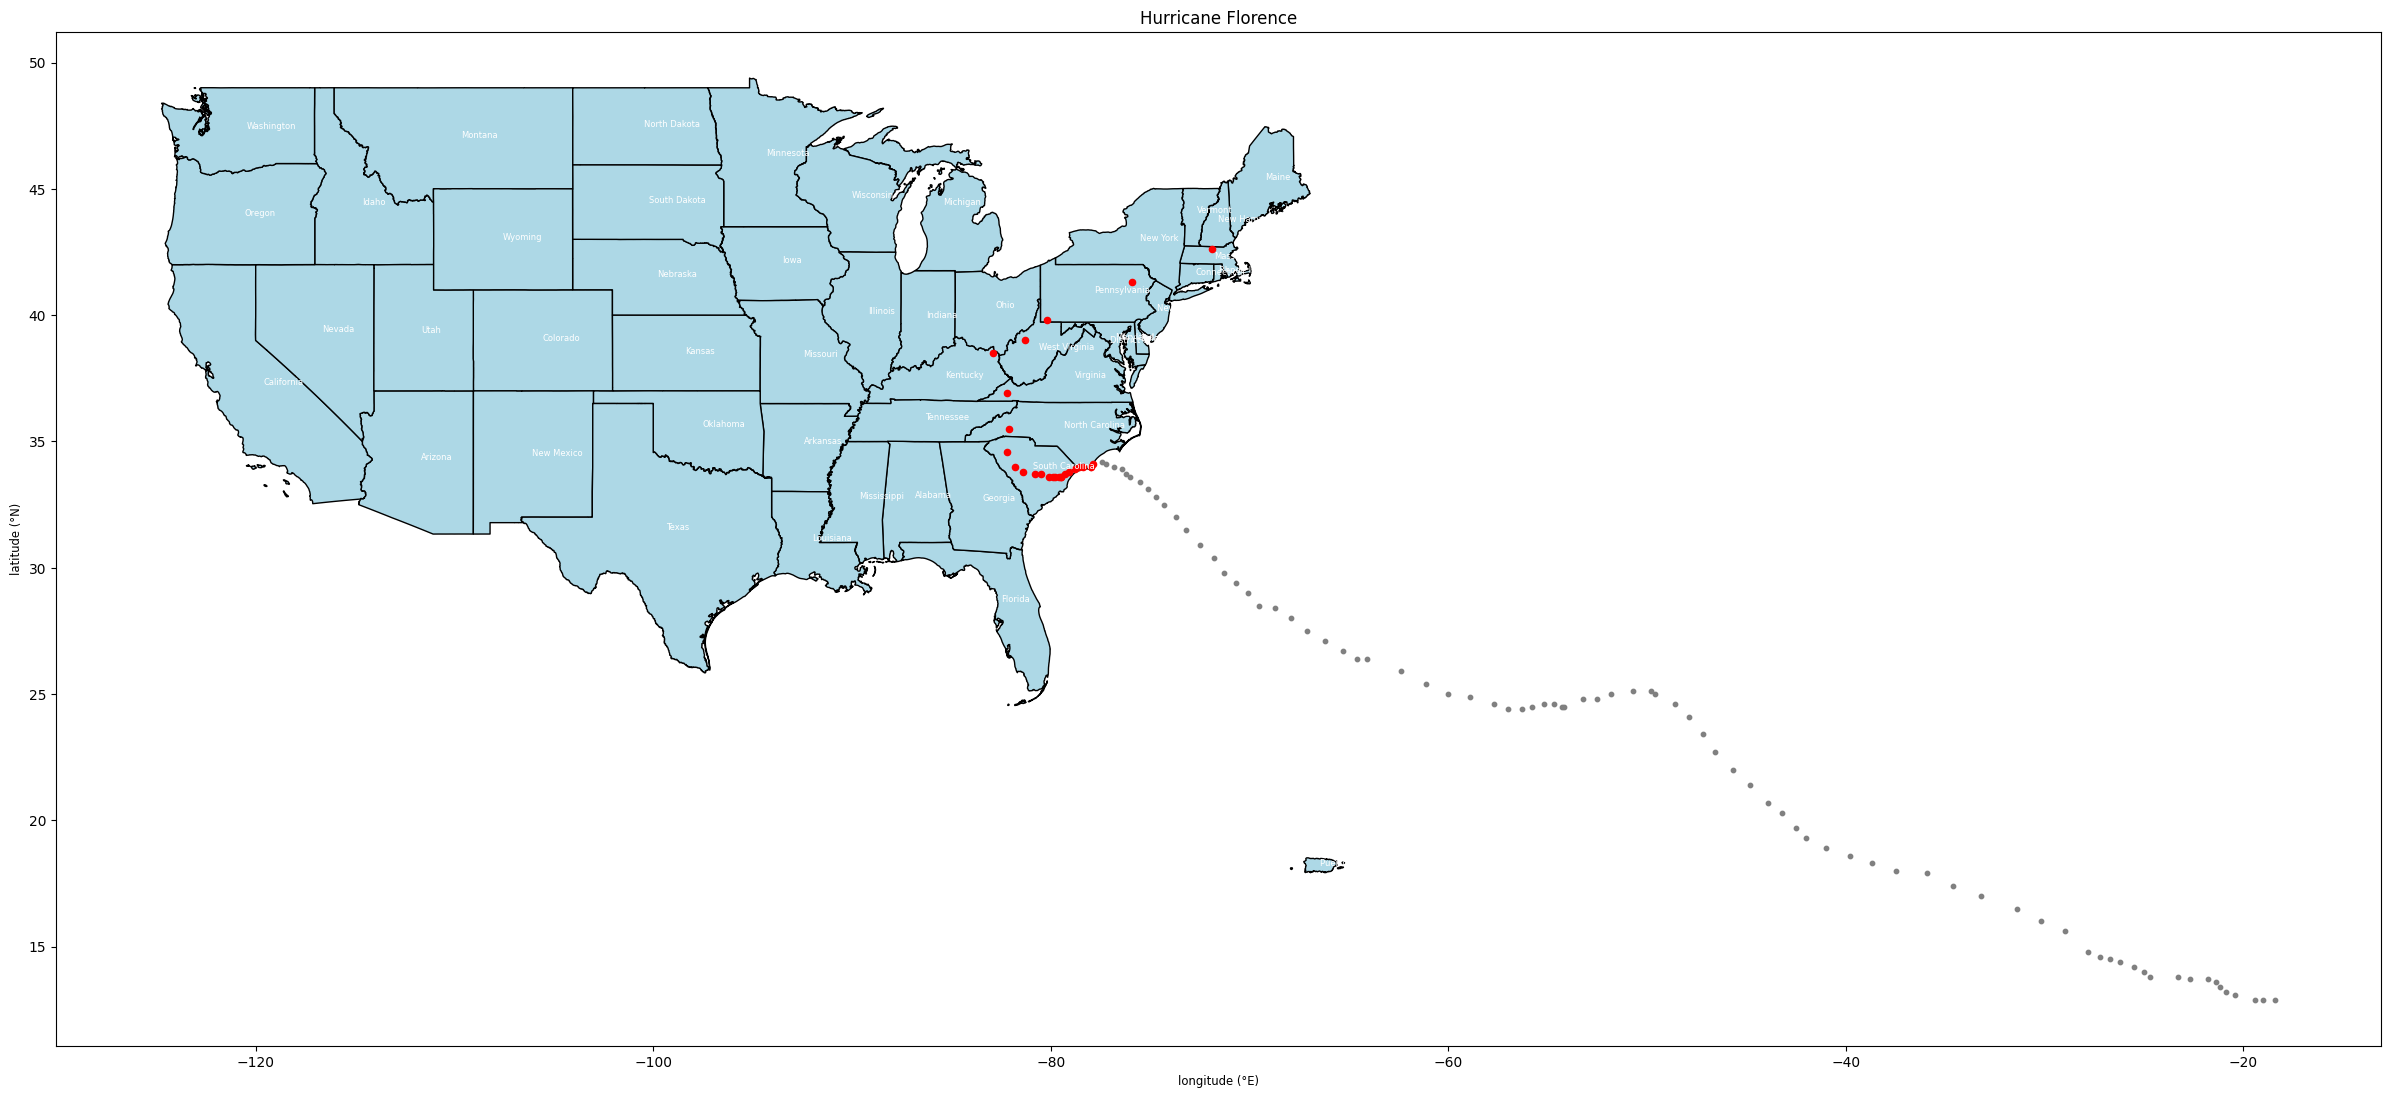

,Date,Lat,Long,Wind,Pres,Movement,Type,Name,geometry,index_right,GEO_ID,STATE,NAME,LSAD,CENSUSAREA
80,09/14/2018 08:00,34.1,-77.9,90,958,WNW at 6 MPH (260 deg),Hurricane,Florence,POINT (-77.9 34.1),33,0400000US37,37,North Carolina,,48617.905
81,09/14/2018 11:00,34.0,-78.0,80,958,WSW at 3 MPH (245 deg),Hurricane,Florence,POINT (-78 34),33,0400000US37,37,North Carolina,,48617.905
82,09/14/2018 14:00,34.0,-78.4,75,968,W at 5 MPH (270 deg),Hurricane,Florence,POINT (-78.4 34),33,0400000US37,37,North Carolina,,48617.905
83,09/14/2018 17:00,34.0,-78.6,70,972,W at 3 MPH (270 deg),Tropical Storm,Florence,POINT (-78.6 34),33,0400000US37,37,North Carolina,,48617.905
84,09/14/2018 20:00,33.9,-78.8,70,975,W at 3 MPH (270 deg),Tropical Storm,Florence,POINT (-78.8 33.9),40,0400000US45,45,South Carolina,,30060.696
85,09/14/2018 23:00,33.8,-79.1,65,980,WSW at 5 MPH (255 deg),Tropical Storm,Florence,POINT (-79.1 33.8),40,0400000US45,45,South Carolina,,30060.696
86,09/15/2018 02:00,33.7,-79.3,60,984,WSW at 5 MPH (255 deg),Tropical Storm,Florence,POINT (-79.3 33.7),40,0400000US45,45,South Carolina,,30060.696
87,09/15/2018 05:00,33.6,-79.5,50,986,WSW at 5 MPH (255 deg),Tropical Storm,Florence,POINT (-79.5 33.6),40,0400000US45,45,South Carolina,,30060.696
88,09/15/2018 08:00,33.6,-79.5,50,989,W at 2 MPH (260 deg),Tropical Storm,Florence,POINT (-79.5 33.6),40,0400000US45,45,South Carolina,,30060.696
89,09/15/2018 11:00,33.6,-79.6,45,995,W at 2 MPH (270 deg),Tropical Storm,Florence,POINT (-79.6 33.6),40,0400000US45,45,South Carolina,,30060.696


In [48]:
#Import library
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

# Read the datas with the geopandas and pandas function
country = gpd.read_file(states_path)
florence = pd.read_csv(track_path)

#prepare the data
# HERE IT WORKS !!
florence = florence.drop(["AdvisoryNumber", "Forecaster", "Received"], axis=1)
florence["Long"] = 0 - florence["Long"]

# Plot the US states (Alaska and Hawaii excluded)
# HERE IT WORKS !!
US = country[~country["NAME"].isin(["Hawaii", "Alaska"])]

# Create a geodataframe from the hurricane florence dataframe
gdf_florence = gpd.GeoDataFrame(
    florence,
    geometry=gpd.points_from_xy(florence["Long"], florence["Lat"]),
    crs="EPSG:4326")

# Plot
florence_inside = gpd.sjoin(gdf_florence, US, how='inner', predicate='intersects')

fig, ax = plt.subplots(figsize=(30, 20))
US.plot(ax=ax, color="lightblue", edgecolor="black")

# Red Marker
gdf_florence.plot(ax=ax, color="grey", markersize=10)
florence_inside.plot(ax=ax, color="red", markersize=20)

# Give a name
# HERE IT WORKS !!
for name, geom in zip(US["NAME"], US.geometry):
    centroid = geom.centroid
    ax.annotate(text=name, xy=(centroid.x, centroid.y),ha="center", fontsize=6, color="white")

ax.set_xlabel("longitude (°E)")
ax.set_ylabel("latitude (°N)")
ax.set_title("Hurricane Florence")
plt.show()

#Show the intersect
florence_inside.head(30)